# Classificação de células com malária: EDA, divisão dos dados e experimentos

Projeto da disciplina SIN 393 – Introdução à Visão Computacional (2026), UFV Campus Rio Paranaíba.

Dataset: [Cell Images for Detecting Malaria](https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria) (Kaggle)

Este notebook baixa o dataset, faz a análise exploratória e a divisão estratificada em treino, validação e teste, define o pré-processamento com data augmentation e treina duas arquiteturas, ResNet-18 e MobileNetV2, com pesos pré-treinados na ImageNet e com pesos aleatórios, usando 10%, 25% e 100% do conjunto de treino. Os modelos são avaliados no conjunto de teste com métricas, matrizes de confusão, exemplos de erros e teste de McNemar.

Sumário
1. Configuração do ambiente (GPU)
2. Download do dataset
3. Carregando os dados
4. Análise exploratória
5. Divisão em treino, validação e teste
6. Pré-processamento e data augmentation
7. Configuração do modelo e hiperparâmetros
8. Experimentos: construção dos modelos, treinos com semente fixa, frações de dados, métricas, matrizes de confusão, análise de erros e exportação dos resultados
9. Curvas de aprendizado da primeira execução

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Configuração do ambiente
Antes de rodar, ative a GPU em **Ambiente de execução → Alterar tipo de ambiente de execução → T4 GPU**.
A célula abaixo confirma que a GPU está disponível (deve aparecer "Tesla T4").


In [ ]:
!nvidia-smi

Sat Nov 14 13:01:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Download do dataset
O download usa a API do Kaggle. O token fica guardado nos **Secrets** do Colab (ícone 🔑 na barra lateral) com o nome `KAGGLE_API_TOKEN` e o acesso ao notebook ativado.


In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [ ]:
!pip install -q kaggle
!kaggle datasets download -d iarunava/cell-images-for-detecting-malaria
!unzip -q cell-images-for-detecting-malaria.zip -d data

Dataset URL: https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria
License(s): unknown
100% 675M/675M [00:07<00:00, 89.5MB/s]



Conferindo a estrutura de pastas. Dentro de `data/cell_images` existem `Parasitized`, `Uninfected` e uma pasta `cell_images` aninhada, que é uma **cópia duplicada e deve ser ignorada**.

In [ ]:
!ls data
!ls data/cell_images

cell_images
cell_images  Parasitized  Uninfected


## 3. Carregando os dados
Listamos todas as imagens `.png` das duas classes em um DataFrame (caminho + rótulo), usando apenas `Parasitized` e `Uninfected`.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("data/cell_images")
classes = ["Parasitized", "Uninfected"]

rows = []
for c in classes:
    for p in (BASE / c).glob("*.png"):   # só .png, ignora arquivos como Thumbs.db
        rows.append({"path": str(p), "label": c})

df = pd.DataFrame(rows)
print(len(df))
print(df["label"].value_counts())

27558
label
Parasitized    13779
Uninfected     13779
Name: count, dtype: int64


## 4. Análise exploratória (EDA)

### 4.1 Balanceamento das classes
Verificamos se as classes têm quantidades parecidas. Isso define quais métricas são confiáveis e se será preciso tratar desbalanceamento.

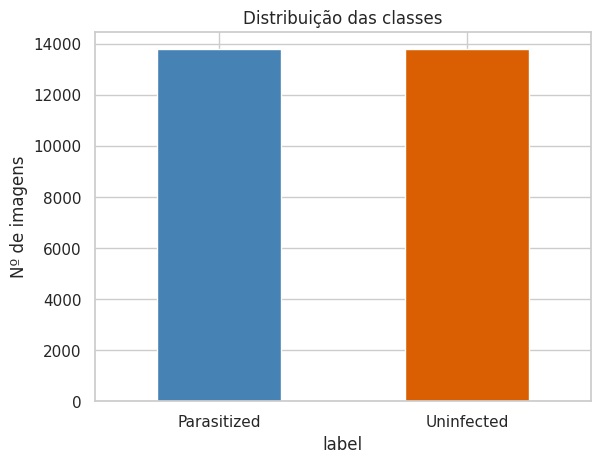

In [ ]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(kind="bar", color=["#4682b4", "#d95f02"])
plt.title("Distribuição das classes")
plt.ylabel("Nº de imagens")
plt.xticks(rotation=0)
plt.show()

### 4.2 Exemplos de imagens
Quatro imagens aleatórias de cada classe (semente fixa). Esta figura pode ser usada na introdução do artigo.

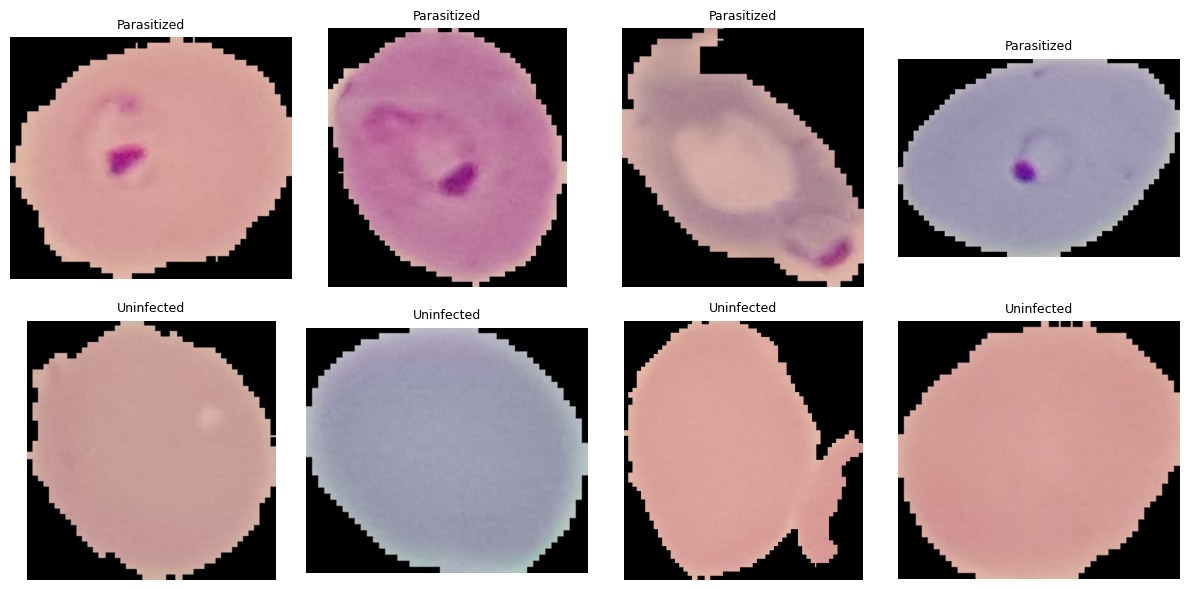

In [ ]:
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, c in enumerate(classes):
    amostra = df[df["label"] == c].sample(4, random_state=42)
    for j, (_, r) in enumerate(amostra.iterrows()):
        axes[i, j].imshow(Image.open(r["path"]))
        axes[i, j].set_title(c, fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.savefig("amostras.png", dpi=150)
plt.show()

### 4.3 Tamanhos das imagens e arquivos corrompidos
As imagens têm resoluções diferentes, então será necessário um **resize** no pipeline. Também verificamos se há arquivos corrompidos.

In [ ]:
import numpy as np

tamanhos, corrompidas = [], []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            tamanhos.append(im.size)   # (largura, altura)
    except Exception:
        corrompidas.append(p)

larg = np.array([t[0] for t in tamanhos])
alt = np.array([t[1] for t in tamanhos])
print("Corrompidas:", len(corrompidas))
print("Largura  min/média/máx:", larg.min(), larg.mean().round(1), larg.max())
print("Altura   min/média/máx:", alt.min(), alt.mean().round(1), alt.max())

Corrompidas: 0
Largura  min/média/máx: 46 132.5 394
Altura   min/média/máx: 40 133.0 385


**Conclusões da EDA**
- 27.558 imagens, 13.779 por classe: dataset perfeitamente balanceado.
- Nenhuma imagem corrompida.
- Resolução variável (46–394 px de largura, 40–385 px de altura, média ≈ 133×133): será necessário redimensionar.

## 5. Divisão treino / validação / teste
Divisão **estratificada** 70% / 15% / 15% com `train_test_split` e **semente fixa** (`SEED = 42`).
O conjunto de teste só será usado na avaliação final dos modelos.

In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

# 70% treino e 30% (validação + teste)
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED
)
# divide os 30% ao meio: 15% validação e 15% teste
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

for nome, d in [("treino", train_df), ("validação", val_df), ("teste", test_df)]:
    print(nome, len(d), d["label"].value_counts().to_dict())

treino 19290 {'Uninfected': 9645, 'Parasitized': 9645}
validação 4134 {'Parasitized': 2067, 'Uninfected': 2067}
teste 4134 {'Parasitized': 2067, 'Uninfected': 2067}


Salvamos a divisão em CSV. Esses arquivos devem ir para o GitHub (pasta `splits/`) para que todos os experimentos usem **exatamente a mesma divisão**.

In [ ]:
import os
os.makedirs("splits", exist_ok=True)

train_df.to_csv("splits/train.csv", index=False)
val_df.to_csv("splits/val.csv", index=False)
test_df.to_csv("splits/test.csv", index=False)

In [ ]:
# Backup local do split (rodar só se precisar baixar os CSVs de novo)
# !zip -r splits.zip splits
# from google.colab import files
# files.download("splits.zip")

## 6. Pré-processamento e data augmentation

Treino, validação e teste passam por *resize* e normalização (média e desvio do ImageNet, usados nos modelos pré-treinados). **Apenas o conjunto de treino recebe aumento de dados**, para que validação e teste meçam o desempenho em imagens sem alteração.

In [ ]:
import torch
from torchvision import transforms

IMG_SIZE = 224   # alternativa: 128 (treina mais rápido)
MEAN = [0.485, 0.456, 0.406]   # ImageNet
STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_tf = transforms.Compose([   # validação e teste: sem aumento
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

### Justificativa das transformações

- **Flips horizontal e vertical e rotação:** células ao microscópio não têm orientação fixa, então essas variações são realistas e ensinam o modelo a não depender da posição.
- **Variação leve de brilho, contraste e saturação:** a iluminação e a coloração das lâminas variam entre amostras.
- **Matiz (hue) quase fixo (0,02):** a cor da coloração é pista diagnóstica (o parasita aparece com tom mais escuro), então alterá-la muito poderia destruir informação útil.
- **Sem recortes agressivos:** um recorte poderia remover o parasita e deixar a imagem com o rótulo errado.

### Dataset do PyTorch

A classe abaixo lê o caminho de cada imagem no DataFrame, abre a imagem, aplica a transformação e devolve o par (imagem, rótulo). Codificação: `Uninfected = 0` e `Parasitized = 1` (classe positiva).

In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

CLASS_TO_IDX = {"Uninfected": 0, "Parasitized": 1}

class MalariaDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row["path"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, CLASS_TO_IDX[row["label"]]

train_ds = MalariaDataset(train_df, train_tf)
val_ds   = MalariaDataset(val_df, eval_tf)
test_ds  = MalariaDataset(test_df, eval_tf)
print(len(train_ds), len(val_ds), len(test_ds))

19290 4134 4134


### Visualizando o efeito do data augmentation

Uma imagem do treino, ao lado de 5 versões geradas pelas transformações aleatórias. Serve para conferir que o aumento não deforma demais as células.

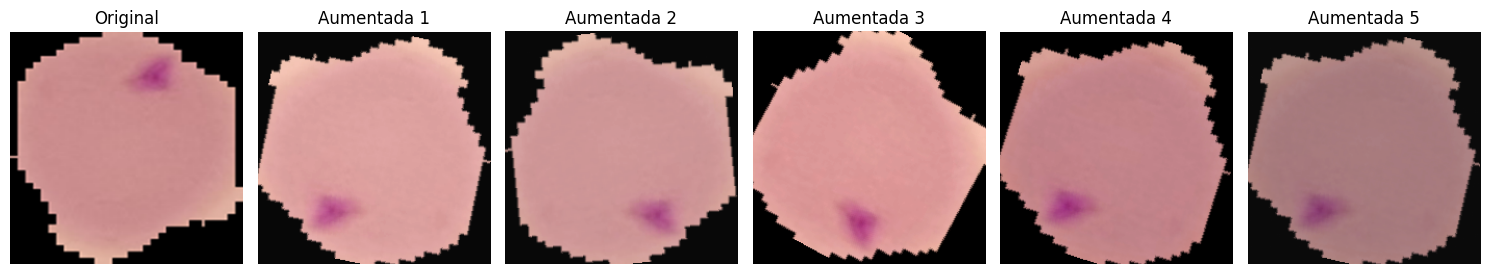

In [ ]:
import matplotlib.pyplot as plt

def desnormalizar(t):
    m = torch.tensor(MEAN).view(3, 1, 1)
    s = torch.tensor(STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

row = train_df[train_df["label"] == "Parasitized"].iloc[0]
img = Image.open(row["path"]).convert("RGB")

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(img.resize((IMG_SIZE, IMG_SIZE)))
axes[0].set_title("Original")
for k in range(1, 6):
    axes[k].imshow(desnormalizar(train_tf(img)))
    axes[k].set_title(f"Aumentada {k}")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.savefig("augmentation.png", dpi=150)
plt.show()

### DataLoaders

Os DataLoaders entregam as imagens em lotes (*batches*). O treino é embaralhado a cada época; validação e teste, não.

In [ ]:
BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

x, y = next(iter(train_loader))
print(x.shape, y.shape)

torch.Size([64, 3, 224, 224]) torch.Size([64])


## 7. Configuração do modelo e hiperparâmetros
- **Dispositivo**: Verificação de disponibilidade de aceleração via GPU (`cuda`).
- **Modelo Base**: Teste inicial utilizando a arquitetura **ResNet-18** pré-treinada na ImageNet. A última camada linear (`fc`) foi adaptada para saída de **2 classes** (`Uninfected` e `Parasitized`).
- **Função de Perda**: `CrossEntropyLoss`, adequada para tarefas de classificação de imagens.
- **Otimizador**: `Adam` com taxa de aprendizado de $10^{-4}$.

### Funções de ciclo de treino e validação
- `train_epoch()`: Altera o modelo para o modo de treino (`model.train()`), executa o *forward pass*, calcula a perda, realiza a retropropagação (*backward pass*) e atualiza os pesos com `optimizer.step()`.
- `eval_epoch()`: Altera o modelo para o modo de avaliação (`model.eval()`) e desativa o cálculo de gradientes (`torch.no_grad()`) para medir o desempenho de validação com menor consumo de memória.

### Teste de validação do pipeline (*Sanity Check*)
Execução do treinamento por apenas **2 épocas** para validar o funcionamento do fluxo completo e evitar erros antes dos experimentos oficiais.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# 1. Definir o dispositivo (GPU se disponível)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Treinando no dispositivo: {device}")

# 2. Instanciar 1 modelo pré-treinado para teste (ex: ResNet18)
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
# Ajustar a última camada para 2 classes (Uninfected e Parasitized)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model = model.to(device)

# 3. Definir a Função de Perda e o Otimizador
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# 4. Função de Treinamento por Época
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    all_preds, all_labels = [], []

    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    return epoch_loss, epoch_acc

# 5. Função de Validação por Época
def eval_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    return epoch_loss, epoch_acc

Treinando no dispositivo: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s]


In [ ]:
# Teste rápido de 2 épocas, só para validar o pipeline (registro, não roda mais)
NUM_EPOCHS = 2

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = eval_epoch(model, val_loader, criterion, device)

    print(f"Época {epoch+1}/{NUM_EPOCHS} | "
          f"Treino Loss: {train_loss:.4f} - Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} - Acc: {val_acc:.4f}")

Época 1/2 | Treino Loss: 0.1333 - Acc: 0.9511 | Val Loss: 0.0959 - Acc: 0.9678
Época 2/2 | Treino Loss: 0.1046 - Acc: 0.9630 | Val Loss: 0.0853 - Acc: 0.9690


## 08 – Função construtora dos modelos (build_model)

**Objetivo:** Cria uma função dinâmica em PyTorch capaz de instanciar as duas arquiteturas escolhidas (**ResNet-18** e **MobileNet_V2**), alternando entre pesos pré-treinados da ImageNet (*Transfer Learning*) e inicialização aleatória (treino do zero), ajustando a camada final de saída para 2 classes (`Uninfected` e `Parasitized`).

In [ ]:
import torch
import torch.nn as nn
from torchvision import models

def build_model(arch_name, pretrained=True, num_classes=2):
    """
    Instancia e adapta a arquitetura escolhida para o problema de 2 classes.
    """
    if arch_name == 'resnet18':
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        model = models.resnet18(weights=weights)
        # Adaptar a última camada totalmente conectada (fc)
        num_ftrs = model.fc.in_features
        model.fc = nn.Linear(num_ftrs, num_classes)

    elif arch_name == 'mobilenet_v2':
        weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
        model = models.mobilenet_v2(weights=weights)
        # Adaptar a última camada do classificador
        num_ftrs = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(num_ftrs, num_classes)

    else:
        raise ValueError(f"Arquitetura '{arch_name}' não suportada.")

    return model

print("Função build_model definida com sucesso!")

Função build_model definida com sucesso!


### 08.1 Grade de configuração dos experimentos

A matriz experimental cruza duas arquiteturas, ResNet-18 e MobileNetV2, com duas condições de inicialização: pesos pré-treinados na ImageNet (transfer learning) ou pesos aleatórios (treino do zero). Todas as configurações usam a mesma divisão dos dados, o mesmo data augmentation, o otimizador Adam, lote de 64 imagens e 10 épocas.

A taxa de aprendizado é o único outro parâmetro que muda. Os modelos pré-treinados usam 1e-4, para ajustar os pesos sem destruir o que já aprenderam. Os modelos treinados do zero usam 1e-3, porque partem de pesos aleatórios e toleram passos maiores. Como a taxa muda junto com a inicialização, essa comparação mede duas receitas de treino e não isola o efeito dos pesos. Esse efeito não foi separado nos experimentos, e isso limita a conclusão sobre o papel isolado dos pesos pré-treinados.

- A-PT: ResNet-18 com transfer learning, taxa de aprendizado 1e-4
- A-ZERO: ResNet-18 treinada do zero, taxa de aprendizado 1e-3
- B-PT: MobileNetV2 com transfer learning, taxa de aprendizado 1e-4
- B-ZERO: MobileNetV2 treinada do zero, taxa de aprendizado 1e-3

In [ ]:
# Parâmetros gerais
NUM_EPOCHS = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Grade de experimentos: 2 arquiteturas x 2 inicializações
experiments = [
    {'code': 'A-PT',   'arch': 'resnet18',     'pretrained': True,  'lr': 1e-4},
    {'code': 'A-ZERO', 'arch': 'resnet18',     'pretrained': False, 'lr': 1e-3},
    {'code': 'B-PT',   'arch': 'mobilenet_v2', 'pretrained': True,  'lr': 1e-4},
    {'code': 'B-ZERO', 'arch': 'mobilenet_v2', 'pretrained': False, 'lr': 1e-3},
]

print(f"Dispositivo: {device}")
print(f"{len(experiments)} experimentos carregados, {NUM_EPOCHS} épocas cada.")

Dispositivo: cuda
4 experimentos carregados, 10 épocas cada.


### 08.2 Primeira execução: loop de treinamento e registro de históricos

Objetivo: executar em sequência os quatro experimentos, registrando a loss e a acurácia de cada época e exportando os históricos em arquivos `.csv`.

Esta execução não fixou a semente aleatória e não guardou os pesos dos modelos, então serve como registro exploratório. Os resultados reportados no artigo vêm da execução do item 08.4, que usa semente fixa e avalia no conjunto de teste.

In [ ]:
import pandas as pd
import torch.optim as optim

# Dicionário global para guardar os históricos
histories = {}

for exp in experiments:
    code = exp['code']
    print(f"\n==========================================")
    print(f"Iniciando Experimento: {code}")
    print(f"Arquitetura: {exp['arch']} | Pré-treinado: {exp['pretrained']} | LR: {exp['lr']}")
    print(f"==========================================")

    # 1. Instanciar o modelo e enviar para a GPU
    model = build_model(exp['arch'], pretrained=exp['pretrained'], num_classes=2)
    model = model.to(device)

    # 2. Definir perda e otimizador
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=exp['lr'])

    # 3. Estrutura de histórico do experimento
    history = {
        'epoch': [],
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    # 4. Treinamento época por época
    for epoch in range(NUM_EPOCHS):
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = eval_epoch(model, val_loader, criterion, device)

        history['epoch'].append(epoch + 1)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"Época {epoch+1:02d}/{NUM_EPOCHS:02d} | "
              f"Treino Loss: {train_loss:.4f} - Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} - Acc: {val_acc:.4f}")

    # 5. Salvar o histórico em CSV individual
    df_exp = pd.DataFrame(history)
    df_exp['experiment'] = code
    df_exp.to_csv(f"history_{code}.csv", index=False)

    histories[code] = df_exp
    print(f"Arquivo 'history_{code}.csv' salvo com sucesso!")


Iniciando Experimento: A-PT
Arquitetura: resnet18 | Pré-treinado: True | LR: 0.0001
Época 01/10 | Treino Loss: 0.1320 - Acc: 0.9542 | Val Loss: 0.0861 - Acc: 0.9673
Época 02/10 | Treino Loss: 0.1048 - Acc: 0.9641 | Val Loss: 0.0777 - Acc: 0.9727
Época 03/10 | Treino Loss: 0.0929 - Acc: 0.9672 | Val Loss: 0.0718 - Acc: 0.9731
Época 04/10 | Treino Loss: 0.0833 - Acc: 0.9714 | Val Loss: 0.0765 - Acc: 0.9746
Época 05/10 | Treino Loss: 0.0830 - Acc: 0.9701 | Val Loss: 0.1025 - Acc: 0.9630
Época 06/10 | Treino Loss: 0.0814 - Acc: 0.9712 | Val Loss: 0.0694 - Acc: 0.9739
Época 07/10 | Treino Loss: 0.0762 - Acc: 0.9733 | Val Loss: 0.0697 - Acc: 0.9751
Época 08/10 | Treino Loss: 0.0747 - Acc: 0.9738 | Val Loss: 0.0828 - Acc: 0.9683
Época 09/10 | Treino Loss: 0.0702 - Acc: 0.9761 | Val Loss: 0.0654 - Acc: 0.9761
Época 10/10 | Treino Loss: 0.0697 - Acc: 0.9744 | Val Loss: 0.0675 - Acc: 0.9775
Arquivo 'history_A-PT.csv' salvo com sucesso!

Iniciando Experimento: A-ZERO
Arquitetura: resnet18 | Pré-

100%|██████████| 13.6M/13.6M [00:00<00:00, 125MB/s]


Época 01/10 | Treino Loss: 0.1708 - Acc: 0.9396 | Val Loss: 0.0941 - Acc: 0.9698
Época 02/10 | Treino Loss: 0.1099 - Acc: 0.9626 | Val Loss: 0.0848 - Acc: 0.9695
Época 03/10 | Treino Loss: 0.0955 - Acc: 0.9667 | Val Loss: 0.0810 - Acc: 0.9710
Época 04/10 | Treino Loss: 0.0888 - Acc: 0.9695 | Val Loss: 0.0748 - Acc: 0.9744
Época 05/10 | Treino Loss: 0.0852 - Acc: 0.9711 | Val Loss: 0.0749 - Acc: 0.9741
Época 06/10 | Treino Loss: 0.0798 - Acc: 0.9731 | Val Loss: 0.0722 - Acc: 0.9753
Época 07/10 | Treino Loss: 0.0765 - Acc: 0.9735 | Val Loss: 0.0692 - Acc: 0.9768
Época 08/10 | Treino Loss: 0.0737 - Acc: 0.9741 | Val Loss: 0.0671 - Acc: 0.9763
Época 09/10 | Treino Loss: 0.0678 - Acc: 0.9756 | Val Loss: 0.0669 - Acc: 0.9763
Época 10/10 | Treino Loss: 0.0649 - Acc: 0.9768 | Val Loss: 0.0668 - Acc: 0.9777
Arquivo 'history_B-PT.csv' salvo com sucesso!

Iniciando Experimento: B-ZERO
Arquitetura: mobilenet_v2 | Pré-treinado: False | LR: 0.001
Época 01/10 | Treino Loss: 0.3031 - Acc: 0.8699 | Val

### 08.3 Consolidação dos resultados da primeira execução

**Objetivo:** Unificar as métricas de todos os experimentos em um único DataFrame e salvar o arquivo `all_experiments_history.csv` para gerar os gráficos comparativos.

In [ ]:
# Unificar todos os DataFrames de histórico
df_all = pd.concat(histories.values(), ignore_index=True)
df_all.to_csv("all_experiments_history.csv", index=False)

print("\nResumo das métricas finais de validação (Época 10):")
print(df_all[df_all['epoch'] == NUM_EPOCHS][['experiment', 'val_loss', 'val_acc']])


Resumo das métricas finais de validação (Época 10):
   experiment  val_loss   val_acc
9        A-PT  0.067505  0.977504
19     A-ZERO  0.162215  0.963716
29       B-PT  0.066793  0.977746
39     B-ZERO  0.105997  0.965409


### 08.4 Nova execução com semente fixa, pesos salvos e avaliação no teste

A primeira execução (itens 08.2 e 08.3) não fixou a semente aleatória e não guardou os pesos dos modelos, então não permite avaliar no conjunto de teste. Esta etapa repete os quatro experimentos com a semente fixa em 42. Em cada um, os pesos da época com menor loss de validação são salvos, e esses pesos são usados uma única vez no conjunto de teste. As previsões ficam em `results/test_preds_*.csv`, e o histórico de treino em `results/history_*.csv`.

In [ ]:
import os, random
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split

os.makedirs("results", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def run_experiment(exp, seed=42, frac=1.0, num_epochs=10):
    set_seed(seed)
    tag = f"{exp['code']}_f{int(frac*100)}_s{seed}"

    # fração estratificada do treino (frac=1.0 usa tudo)
    if frac < 1.0:
        sub_df, _ = train_test_split(train_df, train_size=frac,
                                     stratify=train_df["label"], random_state=seed)
    else:
        sub_df = train_df
    g = torch.Generator()
    g.manual_seed(seed)
    tr_loader = DataLoader(MalariaDataset(sub_df, train_tf), batch_size=BATCH_SIZE,
                           shuffle=True, num_workers=2, generator=g)

    model = build_model(exp["arch"], pretrained=exp["pretrained"]).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=exp["lr"])

    best_val_loss, rows = float("inf"), []
    for epoch in range(1, num_epochs + 1):
        tl, ta = train_epoch(model, tr_loader, criterion, optimizer, device)
        vl, va = eval_epoch(model, val_loader, criterion, device)
        rows.append({"epoch": epoch, "train_loss": tl, "train_acc": ta,
                     "val_loss": vl, "val_acc": va})
        if vl < best_val_loss:
            best_val_loss = vl
            torch.save(model.state_dict(), f"checkpoints/{tag}.pt")
        print(f"{tag} | época {epoch:02d} | treino {tl:.4f}/{ta:.4f} | val {vl:.4f}/{va:.4f}")

    hist = pd.DataFrame(rows)
    hist["experiment"] = exp["code"]
    hist["frac"] = frac
    hist["seed"] = seed
    hist.to_csv(f"results/history_{tag}.csv", index=False)

    # avaliação única no teste, com os pesos da melhor época
    model.load_state_dict(torch.load(f"checkpoints/{tag}.pt"))
    model.eval()
    preds, probs = [], []
    with torch.no_grad():
        for x, _ in test_loader:
            out = model(x.to(device))
            probs.extend(torch.softmax(out, 1)[:, 1].cpu().numpy())
            preds.extend(out.argmax(1).cpu().numpy())

    test_out = test_df.reset_index(drop=True).copy()
    test_out["y_true"] = test_out["label"].map(CLASS_TO_IDX)
    test_out["y_pred"] = preds
    test_out["prob_parasitized"] = probs
    test_out.to_csv(f"results/test_preds_{tag}.csv", index=False)
    print(f"{tag} | acurácia no teste: {(test_out['y_true'] == test_out['y_pred']).mean():.4f}")

In [ ]:
import time
for exp in experiments:
    t0 = time.time()
    run_experiment(exp, seed=42)
    print(f"Tempo de {exp['code']}: {(time.time() - t0)/60:.1f} min\n")

A-PT_f100_s42 | época 01 | treino 0.1357/0.9502 | val 0.0868/0.9693
A-PT_f100_s42 | época 02 | treino 0.1008/0.9655 | val 0.0787/0.9695
A-PT_f100_s42 | época 03 | treino 0.0921/0.9683 | val 0.0688/0.9753
A-PT_f100_s42 | época 04 | treino 0.0833/0.9702 | val 0.0769/0.9717
A-PT_f100_s42 | época 05 | treino 0.0856/0.9697 | val 0.0728/0.9736
A-PT_f100_s42 | época 06 | treino 0.0788/0.9723 | val 0.0626/0.9770
A-PT_f100_s42 | época 07 | treino 0.0754/0.9731 | val 0.0683/0.9763
A-PT_f100_s42 | época 08 | treino 0.0738/0.9735 | val 0.0678/0.9753
A-PT_f100_s42 | época 09 | treino 0.0705/0.9743 | val 0.0683/0.9775
A-PT_f100_s42 | época 10 | treino 0.0706/0.9750 | val 0.0673/0.9751
A-PT_f100_s42 | acurácia no teste: 0.9727
Tempo de A-PT: 24.9 min

A-ZERO_f100_s42 | época 01 | treino 0.2888/0.8821 | val 0.1385/0.9569
A-ZERO_f100_s42 | época 02 | treino 0.1569/0.9507 | val 0.1450/0.9584
A-ZERO_f100_s42 | época 03 | treino 0.1504/0.9500 | val 0.1168/0.9572
A-ZERO_f100_s42 | época 04 | treino 0.1427/

### 08.5 Efeito da quantidade de dados de treino

Para avaliar se o transfer learning ajuda mais quando há poucos dados, os quatro experimentos são repetidos com 10% e 25% do conjunto de treino, amostrados de forma estratificada com a mesma semente. Validação e teste não mudam. Como o número de épocas é o mesmo, os modelos treinados com menos dados recebem menos atualizações de pesos, e isso precisa ser levado em conta na discussão.

In [ ]:
for exp in experiments:
    for frac in [0.10, 0.25]:
        t0 = time.time()
        run_experiment(exp, seed=42, frac=frac)
        print(f"Tempo de {exp['code']} com {int(frac*100)}%: {(time.time() - t0)/60:.1f} min\n")

A-PT_f10_s42 | época 01 | treino 0.2508/0.8953 | val 0.1519/0.9507
A-PT_f10_s42 | época 02 | treino 0.1317/0.9513 | val 0.1314/0.9577
A-PT_f10_s42 | época 03 | treino 0.1131/0.9606 | val 0.1047/0.9620
A-PT_f10_s42 | época 04 | treino 0.0931/0.9694 | val 0.1045/0.9635
A-PT_f10_s42 | época 05 | treino 0.0882/0.9658 | val 0.1033/0.9630
A-PT_f10_s42 | época 06 | treino 0.0898/0.9684 | val 0.1000/0.9661
A-PT_f10_s42 | época 07 | treino 0.0858/0.9699 | val 0.1061/0.9618
A-PT_f10_s42 | época 08 | treino 0.0852/0.9710 | val 0.1130/0.9632
A-PT_f10_s42 | época 09 | treino 0.0736/0.9741 | val 0.1122/0.9596
A-PT_f10_s42 | época 10 | treino 0.0715/0.9762 | val 0.1133/0.9632
A-PT_f10_s42 | acurácia no teste: 0.9635
Tempo de A-PT com 10%: 4.5 min

A-PT_f25_s42 | época 01 | treino 0.1866/0.9255 | val 0.0946/0.9686
A-PT_f25_s42 | época 02 | treino 0.1237/0.9556 | val 0.0839/0.9686
A-PT_f25_s42 | época 03 | treino 0.1064/0.9612 | val 0.0871/0.9676
A-PT_f25_s42 | época 04 | treino 0.1026/0.9612 | val 0.0

### 08.6 Métricas no conjunto de teste

Os quatro modelos treinados com 100% dos dados e semente 42 são avaliados no conjunto de teste, usando os pesos da época com menor loss de validação. A classe positiva é `Parasitized`, então precisão e recall se referem à detecção de células infectadas. O F1 agregado usa a média macro, que coincide com a ponderada porque as duas classes têm o mesmo número de imagens no teste (2.067 cada). Os falsos negativos, células infectadas classificadas como saudáveis, são o erro mais grave em um contexto de diagnóstico.

In [ ]:
import glob, os
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support

CODES = ["A-PT", "A-ZERO", "B-PT", "B-ZERO"]

def carregar(code, frac=100, seed=42):
    return pd.read_csv(f"results/test_preds_{code}_f{frac}_s{seed}.csv")

linhas = []
for code in CODES:
    d = carregar(code)
    y, p = d["y_true"], d["y_pred"]
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[1], zero_division=0)
    _, _, f1_macro, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    linhas.append({
        "Configuração": code,
        "Acurácia": accuracy_score(y, p),
        "Precisão (Parasitized)": pr[0],
        "Recall (Parasitized)": rc[0],
        "F1 (Parasitized)": f1[0],
        "F1 macro": f1_macro,
        "Falsos negativos": fn,
        "Falsos positivos": fp,
    })

metricas = pd.DataFrame(linhas).set_index("Configuração")
print(metricas.round(4))
metricas.round(4).to_csv("results/metricas_teste.csv")

              Acurácia  Precisão (Parasitized)  Recall (Parasitized)  \
Configuração                                                           
A-PT            0.9727                  0.9827                0.9623   
A-ZERO          0.9613                  0.9818                0.9400   
B-PT            0.9705                  0.9855                0.9550   
B-ZERO          0.9632                  0.9733                0.9526   

              F1 (Parasitized)  F1 macro  Falsos negativos  Falsos positivos  
Configuração                                                                  
A-PT                    0.9724    0.9727                78                35  
A-ZERO                  0.9605    0.9613               124                36  
B-PT                    0.9700    0.9705                93                29  
B-ZERO                  0.9628    0.9632                98                54  


### 08.7 Matrizes de confusão

As matrizes mostram, para cada configuração, quantas células de cada classe foram classificadas corretamente e em qual classe foram confundidas. A diagonal principal contém os acertos.

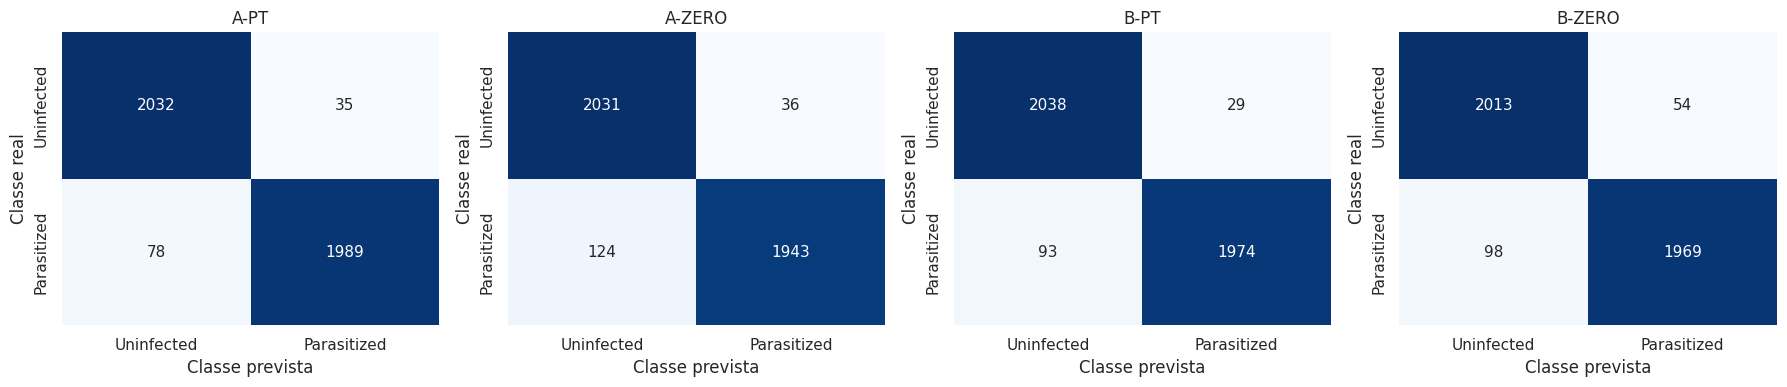

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

nomes = ["Uninfected", "Parasitized"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, code in zip(axes, CODES):
    d = carregar(code)
    cm = confusion_matrix(d["y_true"], d["y_pred"], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=nomes, yticklabels=nomes, ax=ax)
    ax.set_title(code)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
plt.tight_layout()
plt.savefig("results/matrizes_confusao.png", dpi=300)
plt.show()

### 08.8 Desempenho por quantidade de dados de treino

A acurácia no teste é comparada entre as frações de 10%, 25% e 100% do conjunto de treino, para cada configuração. Todos os modelos foram treinados por 10 épocas, então os que usam menos dados recebem menos atualizações de pesos, e isso influencia a comparação.

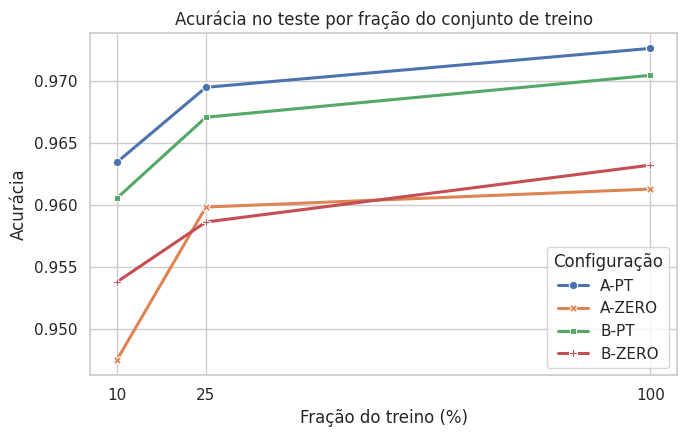

Fração do treino (%)     10      25      100
Configuração                                
A-PT                  0.9635  0.9695  0.9727
A-ZERO                0.9475  0.9598  0.9613
B-PT                  0.9606  0.9671  0.9705
B-ZERO                0.9538  0.9586  0.9632


In [ ]:
registros = []
for code in CODES:
    for frac in [10, 25, 100]:
        d = carregar(code, frac=frac)
        registros.append({"Configuração": code, "Fração do treino (%)": frac,
                          "Acurácia": (d["y_true"] == d["y_pred"]).mean()})
df_frac = pd.DataFrame(registros)

plt.figure(figsize=(7, 4.5))
sns.lineplot(data=df_frac, x="Fração do treino (%)", y="Acurácia", hue="Configuração",
             style="Configuração", markers=True, dashes=False, linewidth=2.2)
plt.xticks([10, 25, 100])
plt.title("Acurácia no teste por fração do conjunto de treino")
plt.tight_layout()
plt.savefig("results/acuracia_por_fracao.png", dpi=300)
plt.show()

print(df_frac.pivot(index="Configuração", columns="Fração do treino (%)", values="Acurácia").round(4))

### 08.9 Análise qualitativa dos erros

A figura mostra exemplos de células classificadas corretamente e incorretamente pelo modelo A-PT no conjunto de teste. As imagens com erro foram sorteadas com semente fixa, sem escolher os casos mais difíceis, para que representem os erros em geral.

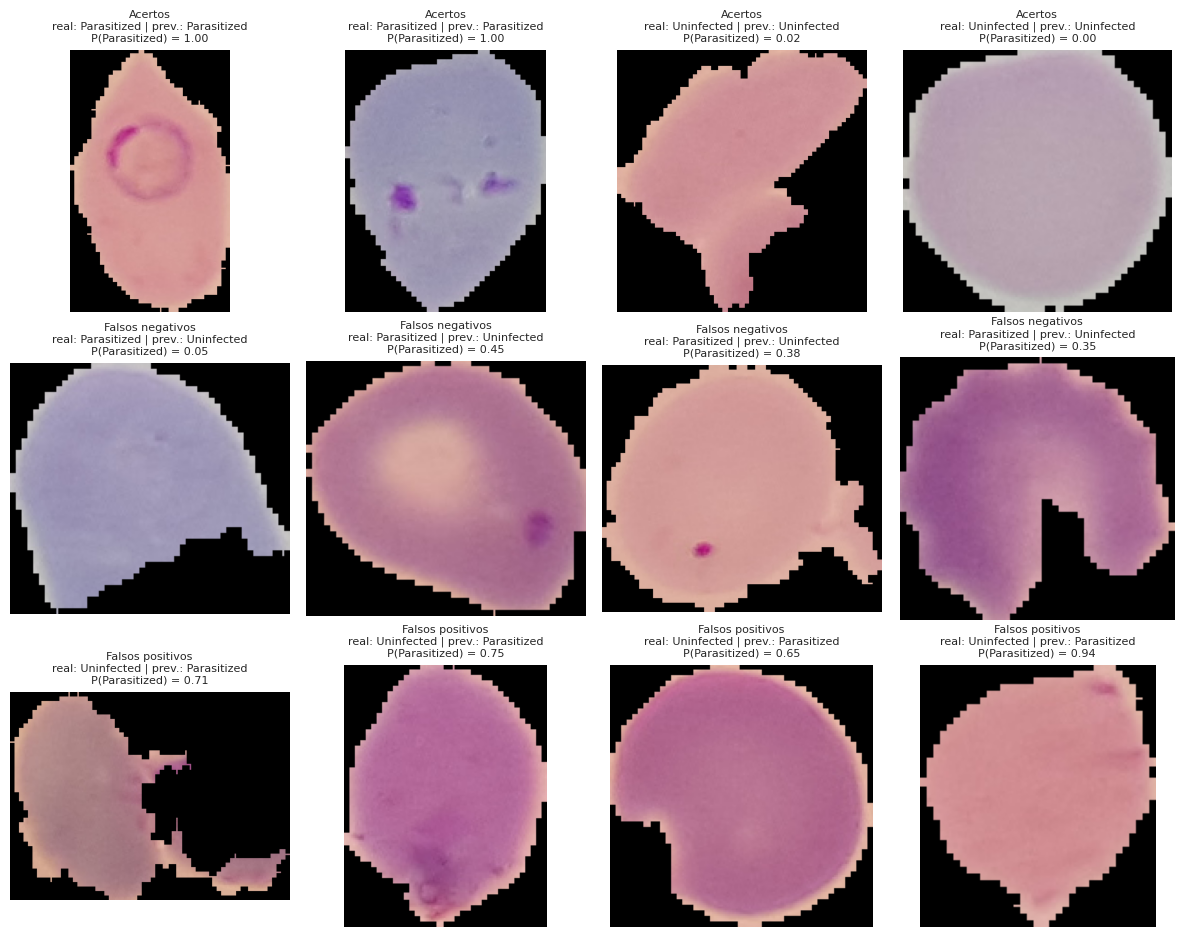

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

d = carregar("A-PT")
nome = {0: "Uninfected", 1: "Parasitized"}

fn = d[(d.y_true == 1) & (d.y_pred == 0)].sample(4, random_state=42)
fp = d[(d.y_true == 0) & (d.y_pred == 1)].sample(4, random_state=42)
ok = pd.concat([d[(d.y_true == 1) & (d.y_pred == 1)].sample(2, random_state=42),
                d[(d.y_true == 0) & (d.y_pred == 0)].sample(2, random_state=42)])

linhas = [("Acertos", ok), ("Falsos negativos", fn), ("Falsos positivos", fp)]
fig, axes = plt.subplots(3, 4, figsize=(12, 9.5))
for i, (titulo, sub) in enumerate(linhas):
    for j, (_, r) in enumerate(sub.iterrows()):
        axes[i, j].imshow(Image.open(r["path"]).convert("RGB"))
        axes[i, j].set_title(f"{titulo}\nreal: {nome[r.y_true]} | prev.: {nome[r.y_pred]}\nP(Parasitized) = {r.prob_parasitized:.2f}", fontsize=8)
        axes[i, j].axis("off")
plt.tight_layout()
plt.savefig("results/exemplos_erros.png", dpi=300)
plt.show()

### 08.10 Teste de McNemar entre pares de modelos

Todos os modelos foram avaliados nas mesmas 4.134 imagens, então os acertos podem ser comparados imagem a imagem. O teste de McNemar considera apenas as imagens em que um modelo acertou e o outro errou e verifica se esse desequilíbrio é maior do que o esperado ao acaso (teste exato, bilateral). Como são quatro comparações, o nível de significância ajustado por Bonferroni é 0,0125.

In [ ]:
from scipy.stats import binomtest

def mcnemar(a, b):
    da, db = carregar(a), carregar(b)
    assert (da["path"] == db["path"]).all()
    ok_a = (da["y_true"] == da["y_pred"]).to_numpy()
    ok_b = (db["y_true"] == db["y_pred"]).to_numpy()
    so_a = int((ok_a & ~ok_b).sum())
    so_b = int((~ok_a & ok_b).sum())
    p = binomtest(so_a, so_a + so_b, 0.5).pvalue
    return {"Modelo A": a, "Modelo B": b, "Só A acertou": so_a, "Só B acertou": so_b, "p-valor": p}

pares = [("A-PT", "A-ZERO"), ("B-PT", "B-ZERO"), ("A-PT", "B-PT"), ("A-ZERO", "B-ZERO")]
tab_mcnemar = pd.DataFrame([mcnemar(a, b) for a, b in pares])
print(tab_mcnemar.round(4))
tab_mcnemar.round(4).to_csv("results/mcnemar.csv", index=False)

  Modelo A Modelo B  Só A acertou  Só B acertou  p-valor
0     A-PT   A-ZERO            82            35   0.0000
1     B-PT   B-ZERO            73            43   0.0068
2     A-PT     B-PT            41            32   0.3492
3   A-ZERO   B-ZERO            29            37   0.3891


### 08.11 Exportação dos resultados

Os históricos e as previsões no teste são compactados para download e versionados no repositório. Os pesos dos modelos (`checkpoints/`) não são enviados ao GitHub.

In [ ]:
!zip -rq results.zip results
from google.colab import files
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 09 – Visualização das curvas de aprendizado comparativas

**Objetivo:** Gerar os gráficos de evolução da Perda (*Loss*) e da Acurácia de Validação ao longo das épocas para comparar o desempenho entre as arquiteturas pré-treinadas (`A-PT`, `B-PT`) e as treinadas do zero (`A-ZERO`, `B-ZERO`).

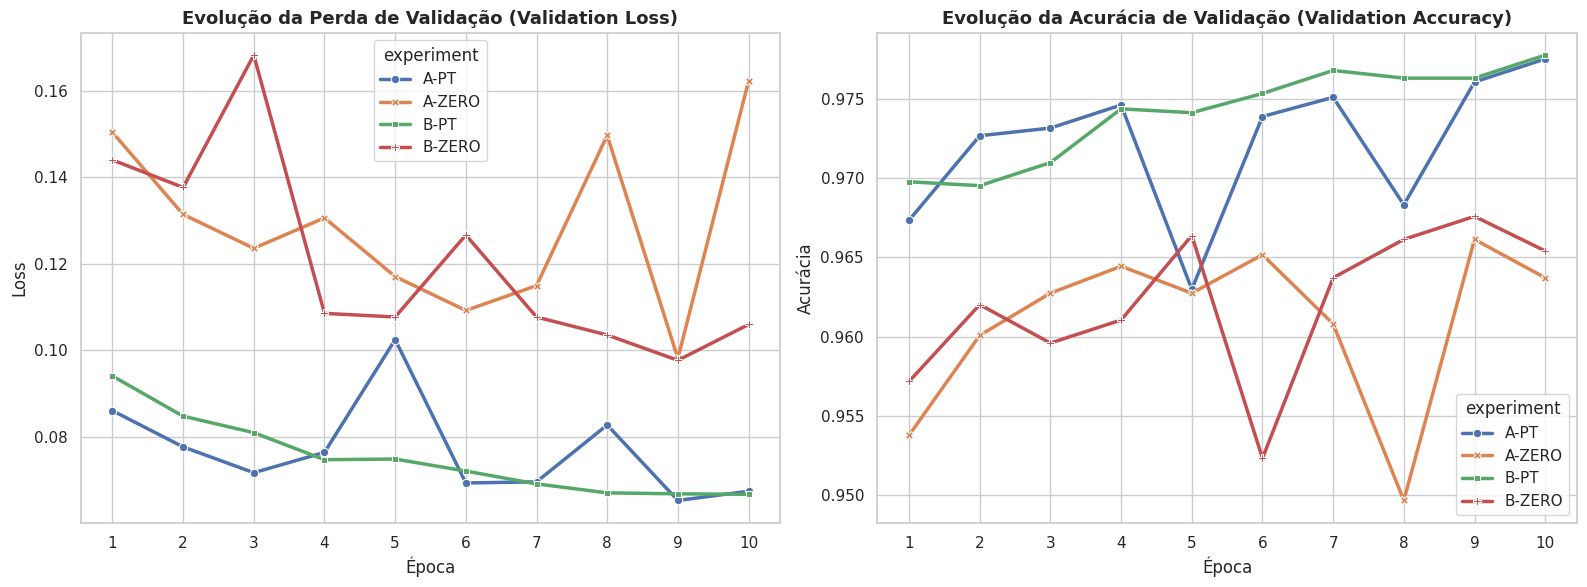

Gráficos comparativos salvos em 'curvas_aprendizado_comparativas.png'!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo visual dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

# 1. Carregar o arquivo de histórico unificado
df_all = pd.read_csv("all_experiments_history.csv")

# 2. Criar painel com 2 subplots lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico da esquerda: Loss de Validação
sns.lineplot(
    data=df_all, x='epoch', y='val_loss', hue='experiment',
    style='experiment', markers=True, dashes=False, linewidth=2.5, ax=axes[0]
)
axes[0].set_title('Evolução da Perda de Validação (Validation Loss)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Loss')
axes[0].set_xticks(range(1, df_all['epoch'].max() + 1))

# Gráfico da direita: Acurácia de Validação
sns.lineplot(
    data=df_all, x='epoch', y='val_acc', hue='experiment',
    style='experiment', markers=True, dashes=False, linewidth=2.5, ax=axes[1]
)
axes[1].set_title('Evolução da Acurácia de Validação (Validation Accuracy)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Acurácia')
axes[1].set_xticks(range(1, df_all['epoch'].max() + 1))

plt.tight_layout()
plt.savefig("curvas_aprendizado_comparativas.png", dpi=300)
plt.show()

print("Gráficos comparativos salvos em 'curvas_aprendizado_comparativas.png'!")

## 09.1 – Ranking de Acurácia Final

**Objetivo:** Apresentar a comparação em formato de gráfico de barras com os percentuais finais alcançados por cada modelo.

/tmp/ipykernel_798/4106779963.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(data=df_final, x='experiment', y='val_acc', palette=palette)


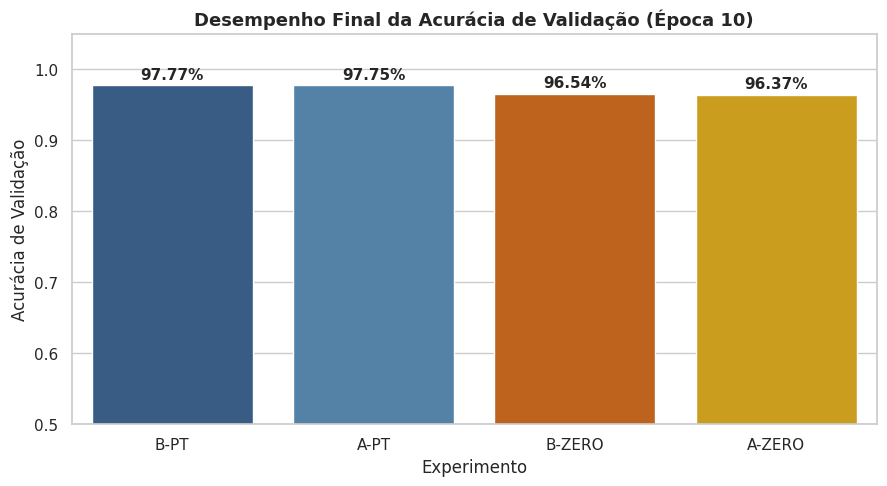

Gráfico de barras salvo em 'acuracia_final_barras.png'!


In [ ]:
# 1. Filtrar as métricas da última época
max_epoch = df_all['epoch'].max()
df_final = df_all[df_all['epoch'] == max_epoch].sort_values(by='val_acc', ascending=False)

# 2. Plotar gráfico de barras
plt.figure(figsize=(9, 5))
palette = ['#2b5c8f', '#4682b4', '#d95f02', '#e6ab02']
barplot = sns.barplot(data=df_final, x='experiment', y='val_acc', palette=palette)

plt.title(f'Desempenho Final da Acurácia de Validação (Época {max_epoch})', fontsize=13, fontweight='bold')
plt.xlabel('Experimento')
plt.ylabel('Acurácia de Validação')
plt.ylim(0.5, 1.05)

# 3. Adicionar as porcentagens no topo de cada barra
for p in barplot.patches:
    height = p.get_height()
    barplot.annotate(f"{height*100:.2f}%",
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='center', xytext=(0, 8),
                     textcoords='offset points', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig("acuracia_final_barras.png", dpi=300)
plt.show()

print("Gráfico de barras salvo em 'acuracia_final_barras.png'!")